## Practical 1 — From Real Biological Data to an ML-Ready Dataset
## Bladder cancer microarray data, data quality, grouping, and batch effects

## Learning goals

By the end of this practical, you should be able to:

- identify observations, features, metadata, targets, and technical variables in a real biological dataset;
- recognize the orientation and dimensionality of an expression matrix;
- apply tidy-data principles to biological measurements and metadata;
- perform systematic data diagnostics even when no obvious data-entry errors are present;
- transform a real expression dataset into an ML-ready representation;
- explain why repeated or highly related observations must remain in the same data split;
- distinguish **real batch structure** from an **artificial pseudo grouping**;
- detect evidence of batch effects and target–batch confounding;
- independently apply the same workflow to the UCI Mice Protein Expression dataset.

**Main idea:** a model sees numerical representations. It does not assume which variation is biological, technical, duplicated, or leaked across the train/test boundary.

# 0. Dataset check


We use the Bioconductor **`bladderbatch`** dataset: an Affymetrix microarray bladder-cancer dataset containing **57 samples, 22,283 probe-set expression measurements, and five processing batches**.

The Bioconductor metadata include:

- `sample` — sample number;
- `outcome` — original biological outcome;
- `batch` — processing batch defined by the date on which arrays were processed;
- `cancer` — a simplified biological outcome.

The expression data were RMA-normalized before inclusion in the package.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

DATA = Path(".")
RANDOM_STATE = 100926

In [2]:
expression_raw = pd.read_csv(DATA / "bladder_expression_raw.csv")
metadata = pd.read_csv(DATA / "bladder_metadata.csv")

print("Raw expression:", expression_raw.shape)
print("Metadata:", metadata.shape)

Raw expression: (22283, 58)
Metadata: (57, 5)


In [3]:
metadata

,sample_id,sample,outcome,batch,cancer
0,GSM71019.CEL,1,Normal,3,Normal
1,GSM71020.CEL,2,Normal,2,Normal
2,GSM71021.CEL,3,Normal,2,Normal
3,GSM71022.CEL,4,Normal,3,Normal
4,GSM71023.CEL,5,Normal,3,Normal
5,GSM71024.CEL,6,Normal,3,Normal
6,GSM71025.CEL,7,Normal,2,Normal
7,GSM71026.CEL,8,Normal,2,Normal
8,GSM71028.CEL,9,sTCC+CIS,5,Cancer
9,GSM71029.CEL,10,sTCC-CIS,2,Cancer


In [4]:
expression_raw.head()

,probe_set_id,GSM71019.CEL,GSM71020.CEL,GSM71021.CEL,GSM71022.CEL,GSM71023.CEL,GSM71024.CEL,GSM71025.CEL,GSM71026.CEL,GSM71028.CEL,...,GSM71068.CEL,GSM71069.CEL,GSM71070.CEL,GSM71071.CEL,GSM71072.CEL,GSM71073.CEL,GSM71074.CEL,GSM71075.CEL,GSM71076.CEL,GSM71077.CEL
0,1007_s_at,10.115170,8.628044,8.779235,9.248569,10.256841,10.023133,9.108034,8.735616,9.803271,...,10.582892,10.009028,9.912853,9.096809,9.011927,8.396062,8.903465,9.501538,9.540766,9.039143
1,1053_at,5.345168,5.063598,5.113116,5.179410,5.181383,5.248418,5.252312,5.220931,5.595771,...,5.615926,5.151548,5.237126,5.093278,5.353248,5.214357,5.251383,5.223598,5.191392,5.235880
2,117_at,6.348024,6.663625,6.465892,6.116422,5.980457,5.796155,6.414849,6.846798,5.841478,...,5.913488,5.904794,5.960948,6.394089,6.425034,6.372520,6.095344,5.811968,6.007461,6.314809
3,121_at,8.901739,9.439977,9.540738,9.254368,8.798086,8.002870,9.093704,9.263386,7.789240,...,8.049998,8.407351,8.985741,8.817789,8.866083,8.704385,9.375736,8.580523,8.848099,9.663298
4,1255_g_at,3.967672,4.466027,4.144885,4.189338,4.078509,3.919740,4.402590,4.173666,3.590649,...,3.775194,3.995371,4.322380,4.141255,3.997644,4.219360,4.454771,4.188310,4.284053,4.877523


## 1.2 Prepare the expression matrix for scikit-learn

The raw export preserves the original assay orientation: probe sets are rows and biological samples are columns. Most scikit-learn workflows/tidy data principles expect the opposite orientation: samples are rows and features are columns.

We now transpose the matrix in Python and use the sample identifiers from the column names as `sample_id`. The resulting `expression` table is the ML-ready expression table used below.

In [5]:
expression = expression_raw.set_index("probe_set_id").T.rename_axis("sample_id").reset_index()
expression.columns.name = None

print(expression_raw.shape)
print(expression.shape)


(22283, 58)
(57, 22284)


In [6]:
expression

,sample_id,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,1405_i_at,...,AFFX-r2-Hs28SrRNA-5_at,AFFX-r2-Hs28SrRNA-M_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
0,GSM71019.CEL,10.115170,5.345168,6.348024,8.901739,3.967672,7.775183,5.655863,4.855069,4.942097,...,5.889822,6.255983,11.772870,11.650434,4.295802,3.902905,3.396659,3.319554,3.637277,3.475397
1,GSM71020.CEL,8.628044,5.063598,6.663625,9.439977,4.466027,7.110154,6.068074,4.971663,4.892139,...,6.875853,6.832614,13.301387,13.092792,4.391424,3.725786,4.011382,3.477539,3.909711,3.710860
2,GSM71021.CEL,8.779235,5.113116,6.465892,9.540738,4.144885,7.248430,5.822590,4.955943,4.991248,...,5.400099,6.301081,13.682598,13.497060,4.380636,4.139661,3.799011,3.491621,3.885286,3.524983
3,GSM71022.CEL,9.248569,5.179410,6.116422,9.254368,4.189338,7.017220,5.659677,5.028884,5.163996,...,5.361622,5.519502,12.136462,11.808322,4.453195,3.838170,3.703706,3.392606,3.762326,3.783900
4,GSM71023.CEL,10.256841,5.181383,5.980457,8.798086,4.078509,7.896419,5.480801,4.838721,5.666031,...,6.549468,7.006766,11.918717,11.822269,4.298520,3.889372,3.530179,3.382881,3.777308,3.439520
5,GSM71024.CEL,10.023133,5.248418,5.796155,8.002870,3.919740,7.944676,5.141930,4.688610,5.635379,...,7.146261,7.351801,11.770457,11.609514,4.180763,3.888782,3.378287,3.341418,3.631794,3.438930
6,GSM71025.CEL,9.108034,5.252312,6.414849,9.093704,4.402590,7.469767,5.757393,5.063306,5.151760,...,4.971877,5.437525,13.252039,13.177725,4.418610,3.917813,3.769529,3.500478,3.928444,3.912421
7,GSM71026.CEL,8.735616,5.220931,6.846798,9.263386,4.173666,7.281925,6.134735,5.001731,4.634037,...,4.795820,5.289338,13.077570,13.140737,4.340074,3.765035,3.781147,3.620815,3.720592,3.591586
8,GSM71028.CEL,9.803271,5.595771,5.841478,7.789240,3.590649,7.367814,5.039009,4.629625,5.850502,...,5.016912,4.600464,10.553368,10.549932,3.866587,3.534812,3.188380,3.203602,3.363358,3.371751
9,GSM71029.CEL,10.168602,5.025180,6.352257,9.834564,4.338196,7.825735,5.571846,4.691905,4.697245,...,6.840086,6.829511,12.468495,12.425069,4.111634,3.859987,3.564584,3.407213,3.766254,3.692182


### First questions

Before doing any transformation, answer:

1. What is one **biological observation**?
2. What is a **feature**?
3. Which table contains biological measurements?
4. Which table contains experimental metadata?
5. Which column could be a prediction target?
6. Which column describes a known technical source of variation?

## 1.3 The dimensionality problem

In [7]:
n_samples = expression.shape[0]
n_features = expression.shape[1] - 1

print("Samples:", n_samples)
print("Expression features:", n_features)
print("p / n =", round(n_features / n_samples, 1))

Samples: 57
Expression features: 22283
p / n = 390.9


In this dataset there are tens of thousands of measured variables but only dozens of biological samples.

This is extremely common in transcriptomics and other omics datasets.

> We are **not** solving the high-dimensional modelling problem today.

# 2. EDA and tidy-data principles

A useful working definition of tidy data is:

> **One observation per row, one variable per column, one value per cell.**


## 2.1 Inspect metadata

In [8]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sample_id  57 non-null     object
 1   sample     57 non-null     int64 
 2   outcome    57 non-null     object
 3   batch      57 non-null     int64 
 4   cancer     57 non-null     object
dtypes: int64(2), object(3)
memory usage: 2.4+ KB


## 2.2 Inspect expression values

In [9]:
gene_cols = [c for c in expression.columns if c != "sample_id"]

expression[gene_cols].describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
1007_s_at,57.0,9.757507,0.627462,8.396062,9.287650,9.911038,10.256841,10.840534
1053_at,57.0,5.428176,0.247518,5.025180,5.237126,5.373810,5.587119,6.076057
117_at,57.0,6.197038,0.450471,5.211550,5.960948,6.116422,6.352257,8.477193
121_at,57.0,8.519904,0.541173,7.389635,8.158816,8.505293,8.866083,9.834564
1255_g_at,57.0,3.985271,0.241307,3.547688,3.824158,3.928739,4.141255,4.877523
1294_at,57.0,7.632357,0.452121,6.749402,7.288989,7.614454,7.952671,8.772693
1316_at,57.0,5.392179,0.320225,4.539403,5.172142,5.352646,5.571846,6.134735
1320_at,57.0,4.774995,0.230396,4.337072,4.638903,4.723609,4.874854,6.009317
1405_i_at,57.0,5.187052,0.844344,4.026040,4.643143,5.043862,5.531440,7.426352
1431_at,57.0,3.726263,0.371369,3.378088,3.564485,3.650139,3.776453,6.184132


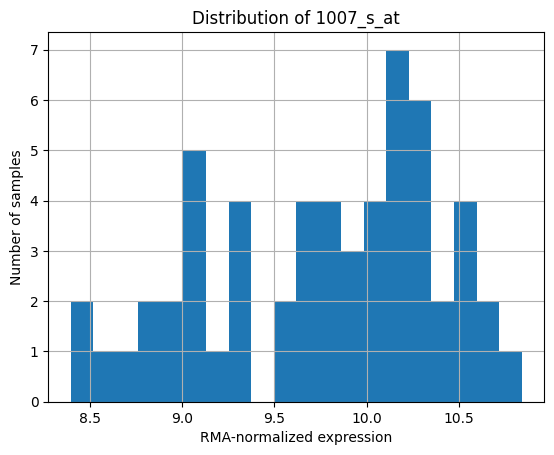

In [10]:
expression[gene_cols[0]].hist(bins=20)
plt.xlabel("RMA-normalized expression")
plt.ylabel("Number of samples")
plt.title(f"Distribution of {gene_cols[0]}")
plt.show()

## 2.3 Biological outcome structure

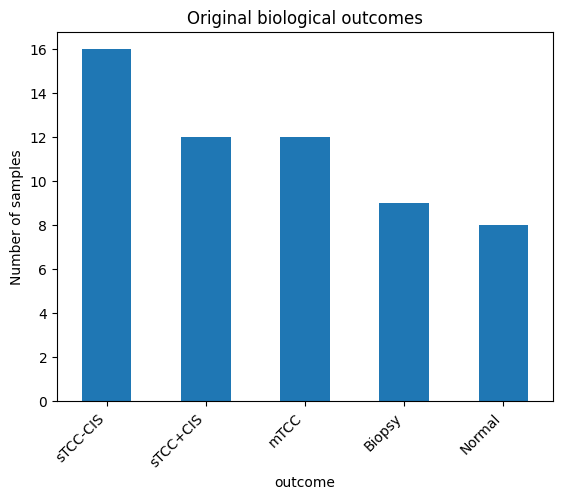

In [11]:
metadata["outcome"].value_counts().plot(kind="bar")
plt.ylabel("Number of samples")
plt.title("Original biological outcomes")
plt.xticks(rotation=45, ha="right")
plt.show()

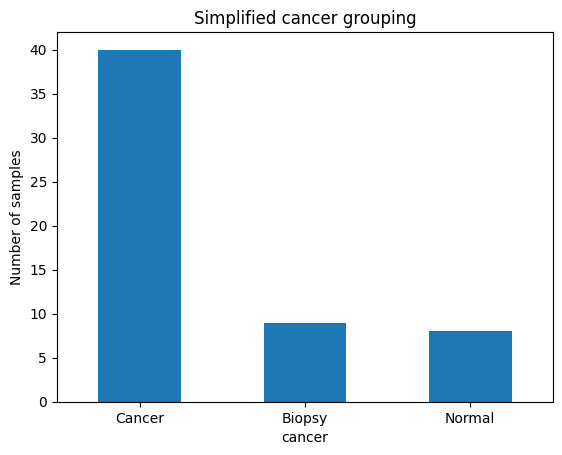

In [12]:
metadata["cancer"].value_counts().plot(kind="bar")
plt.ylabel("Number of samples")
plt.title("Simplified cancer grouping")
plt.xticks(rotation=0)
plt.show()

### Discussion

Why might the original `outcome` and simplified `cancer` variables be useful for different questions?

# 3. Data diagnostics

A diagnostic workflow does **not** mean that we must discover corrupted data.

Real datasets should be checked systematically even when they appear clean.

## 3.1 Are sample identifiers unique?

In [13]:
print("Expression IDs unique:", expression["sample_id"].is_unique)
print("Metadata IDs unique:", metadata["sample_id"].is_unique)

Expression IDs unique: True
Metadata IDs unique: True


## 3.2 Do both tables contain the same samples?

In [14]:
expr_ids = set(expression["sample_id"])
meta_ids = set(metadata["sample_id"])

print("Expression only:", expr_ids - meta_ids)
print("Metadata only:", meta_ids - expr_ids)

Expression only: set()
Metadata only: set()


## 3.4 Exact duplicate samples

In [15]:
print("Duplicate metadata rows:", metadata.duplicated().sum())
print("Duplicate expression rows:", expression.duplicated().sum())

Duplicate metadata rows: 0
Duplicate expression rows: 0


We can also ask whether any two expression rows are numerically identical.

In [16]:
expr_only = expression.set_index("sample_id")
print("Duplicated expression profiles:",
      expr_only.duplicated().sum())

Duplicated expression profiles: 0


## 3.5 Constant and low-variance features

In [17]:
variances = expression[gene_cols].var()

print("Constant features:", (variances == 0).sum())
print("Median feature variance:", variances.median())

Constant features: 0
Median feature variance: 0.1868963225451368


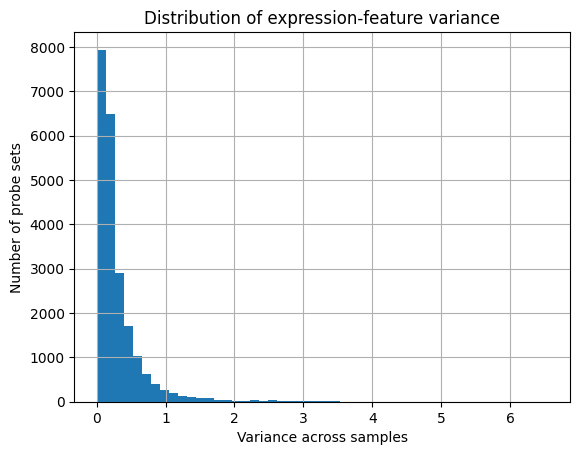

In [18]:
variances.hist(bins=50)
plt.xlabel("Variance across samples")
plt.ylabel("Number of probe sets")
plt.title("Distribution of expression-feature variance")
plt.show()


# 4. Data preparation

## 4.1 Merge measurements and metadata

Because both tables should have one row per sample, we can enforce a one-to-one relationship.

In [19]:
df_real = metadata.merge(
    expression,
    on="sample_id",
    validate="one_to_one")

print(df_real.shape)
df_real.iloc[:5, :10]



(57, 22288)


,sample_id,sample,outcome,batch,cancer,1007_s_at,1053_at,117_at,121_at,1255_g_at
0,GSM71019.CEL,1,Normal,3,Normal,10.115170,5.345168,6.348024,8.901739,3.967672
1,GSM71020.CEL,2,Normal,2,Normal,8.628044,5.063598,6.663625,9.439977,4.466027
2,GSM71021.CEL,3,Normal,2,Normal,8.779235,5.113116,6.465892,9.540738,4.144885
3,GSM71022.CEL,4,Normal,3,Normal,9.248569,5.179410,6.116422,9.254368,4.189338
4,GSM71023.CEL,5,Normal,3,Normal,10.256841,5.181383,5.980457,8.798086,4.078509


## 4.2 Define a possible target

For demonstration, we will use the simplified `cancer` variable as the candidate target.

In [20]:
y_real = df_real["cancer"].copy()
y_real.value_counts()

cancer
Cancer    40
Biopsy     9
Normal     8
Name: count, dtype: int64

## 4.3 Define the real feature matrix

In [21]:
X_real = df_real[gene_cols].copy()

print("X:", X_real.shape)
print("y:", y_real.shape)

X: (57, 22283)
y: (57,)


Notice what is **not** in `X_real`:

- `sample_id`;
- `sample`;
- `outcome`;
- `batch`;
- `cancer`.

Some are identifiers, one is our target, and others are metadata whose inclusion would change the scientific question.




# 5. Artificial within-group similarity for the splitting exercise

The original bladderbatch samples are real biological samples, but the dataset does not provide the repeated-subject structure we want for this exercise. 

We will therefore construct **one pseudo-replicate per real sample** to intentioanlly spoil perfectly good dataset;)

For each real expression profile x_i, we create:

x_i_p = x_i + epsilon

epsilon - small noise

The pseudo-replicate is therefore **highly similar** to its source sample.

## 5.1 Generate pseudo-replicates

In [22]:
rng = np.random.default_rng(RANDOM_STATE)

real = df_real.copy()
real["source_sample_id"] = real["sample_id"]
real["p_group"] = "TG_" + real["sample_id"].astype(str)


pseudo = df_real.copy()
pseudo["source_sample_id"] = pseudo["sample_id"]
pseudo["p_group"] = "TG_" + pseudo["sample_id"].astype(str)


# Give pseudo-replicates unique row/sample identifiers.
pseudo["sample_id"] = pseudo["sample_id"].astype(str) + "_pseudo"

# Small noise relative to the scale ofexpression.
noise_sigma = 0.25
noise = rng.normal(loc=0, scale=noise_sigma, size=(len(pseudo), len(gene_cols)))

pseudo.loc[:, gene_cols] = (pseudo[gene_cols].to_numpy() + noise)

df = pd.concat([real, pseudo], ignore_index=True)

print("Original samples:", len(real))
print("Pseudo-replicates:", len(pseudo))
print("pseudo rows:", len(df))
print("pseudo groups:", df["p_group"].nunique())

Original samples: 57
Pseudo-replicates: 57
pseudo rows: 114
pseudo groups: 57


### Important provenance rule

In [23]:
df[["sample_id", "source_sample_id", "p_group",  "cancer", "batch"]].head(100)

,sample_id,source_sample_id,p_group,cancer,batch
0,GSM71019.CEL,GSM71019.CEL,TG_GSM71019.CEL,Normal,3
1,GSM71020.CEL,GSM71020.CEL,TG_GSM71020.CEL,Normal,2
2,GSM71021.CEL,GSM71021.CEL,TG_GSM71021.CEL,Normal,2
3,GSM71022.CEL,GSM71022.CEL,TG_GSM71022.CEL,Normal,3
4,GSM71023.CEL,GSM71023.CEL,TG_GSM71023.CEL,Normal,3
...,...,...,...,...,...
95,GSM71059.CEL_pseudo,GSM71059.CEL,TG_GSM71059.CEL,Cancer,2
96,GSM71060.CEL_pseudo,GSM71060.CEL,TG_GSM71060.CEL,Cancer,1
97,GSM71061.CEL_pseudo,GSM71061.CEL,TG_GSM71061.CEL,Cancer,5
98,GSM71062.CEL_pseudo,GSM71062.CEL,TG_GSM71062.CEL,Cancer,5


`source_sample_id`, and `p_group` are synthetic metadata.

The original `batch`, `outcome`, and `cancer` values remain those of the real sample.

## 5.2 Verify within-group similarity

Calculate the correlation between every real sample and its pseudo-replicate.

In [24]:
pair_correlations = []

for group, group_df in df.groupby("p_group"):
    if len(group_df) != 2:
        continue

    a = group_df.iloc[0][gene_cols].to_numpy(dtype=float)
    b = group_df.iloc[1][gene_cols].to_numpy(dtype=float)

    pair_correlations.append(np.corrcoef(a, b)[0, 1])

pair_correlations = pd.Series(pair_correlations)

pair_correlations

0     0.988667
1     0.985053
2     0.985383
3     0.986688
4     0.988498
5     0.990382
6     0.986295
7     0.985498
8     0.991439
9     0.987540
10    0.990484
11    0.990573
12    0.990550
13    0.988816
14    0.991196
15    0.990725
16    0.990049
17    0.990832
18    0.990575
19    0.989992
20    0.990883
21    0.990593
22    0.989993
23    0.991862
24    0.988173
25    0.990236
26    0.990778
27    0.988867
28    0.990580
29    0.988300
30    0.990677
31    0.988585
32    0.989745
33    0.990462
34    0.990887
35    0.989501
36    0.989639
37    0.989935
38    0.990465
39    0.991585
40    0.991002
41    0.991028
42    0.991675
43    0.990639
44    0.989077
45    0.991030
46    0.991051
47    0.990998
48    0.989341
49    0.988525
50    0.988374
51    0.988492
52    0.987395
53    0.985109
54    0.988932
55    0.987858
56    0.983029
dtype: float64

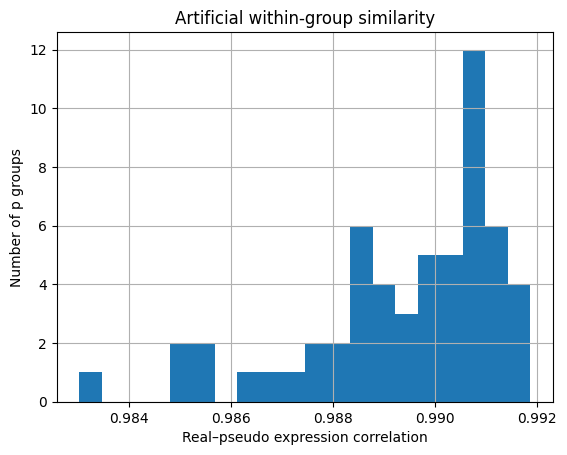

In [25]:
pair_correlations.hist(bins=20)
plt.xlabel("Real–pseudo expression correlation")
plt.ylabel("Number of p groups")
plt.title("Artificial within-group similarity")
plt.show()

## 5.3 Introduce synthetic missing values (pseudoNA)
To spoil our good dataset even more we will intoduce some NA.
We alter expression measurements only; sample identifiers, metadata, targets, and grouping variables remain available for the exercise.

In [26]:
pseudo_na_rng = np.random.default_rng(RANDOM_STATE + 1)

df_pseudona = df.copy()
expression_values = df_pseudona[gene_cols].to_numpy(dtype=float).copy()

# Remove 0.01% of expression cells

pseudo_na_fraction = 0.0001
n_expression_cells = expression_values.size
n_pseudona = max(1, int(round(n_expression_cells * pseudo_na_fraction)))
flat_indices = pseudo_na_rng.choice(
    n_expression_cells,
    size=n_pseudona,
    replace=False
)
rows, columns = np.unravel_index(
    flat_indices,
    expression_values.shape
)
expression_values[rows, columns] = np.nan
df_pseudona.loc[:, gene_cols] = expression_values

print("pseudo rows:", len(df_pseudona))
print("Synthetic missing expression cells:", df_pseudona[gene_cols].isna().sum().sum())

pseudo rows: 114
Synthetic missing expression cells: 254


## 5.4 Missing-value handling: detection, removal, and imputation

Missing values should be handled as part of the data-generating and modelling workflow. Start by detecting where they occur and how much information is affected.

There is no universally correct response:

- **Detection:** inspect missingness by table, row, column, and experimental group.
- **Removal:** remove rows or features only when the loss is acceptable and the rule is scientifically justified. In high-dimensional data, dropping every row with any missing feature can discard most observations.
- **Imputation:** replace missing values using a rule such as a median, mean, K-nearest neighbours, or a model-based method. The imputation rule must be fitted on the training data only, then applied to the test data, so that test-set information does not leak into training.

The following cells are a demonstration using the synthetic pseudoNA copy.

In [27]:
missing_by_column = df_pseudona[gene_cols].isna().sum()
missing_by_row = df_pseudona[gene_cols].isna().sum(axis=1)

print("Total missing expression cells:", int(missing_by_column.sum()))
print("Features with at least one missing value:", int((missing_by_column > 0).sum()))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))

display(missing_by_column[missing_by_column > 0].head())
missing_by_row.describe()

Total missing expression cells: 254
Features with at least one missing value: 253
Rows with at least one missing value: 99


200769_s_at    1
200775_s_at    1
200819_s_at    1
200835_s_at    1
200981_x_at    1
dtype: int64

count    114.000000
mean       2.228070
std        1.545963
min        0.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        7.000000
dtype: float64

### Removal as a possible strategy

Complete-row removal is easy to write, but it can be very costly. Feature removal is another option, although removing a feature because of one missing value may also discard useful measurements. Compare both consequences before choosing a rule.

In [28]:
df_rows_removed = df_pseudona.dropna(subset=gene_cols)
features_without_missing = [
    column for column in gene_cols
    if df_pseudona[column].notna().all()
]
X_features_removed = df_pseudona[features_without_missing].copy()

print("Rows before removal:", len(df_pseudona))
print("Rows after complete-row removal:", len(df_rows_removed))
print("Features before removal:", len(gene_cols))
print("Features after removal of any incomplete feature:", X_features_removed.shape[1])

Rows before removal: 114
Rows after complete-row removal: 15
Features before removal: 22283
Features after removal of any incomplete feature: 22030


### Imputation as a possible strategy

Here we use median imputation as a simple baseline. In a real analysis, the choice should reflect the measurement process and the scientific question. 

In [29]:

X_pseudona = df_pseudona[gene_cols].copy()

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X_pseudona), columns=gene_cols)


X_imputed.isna().sum().sum()

np.int64(0)

# 6. Splits

## 6.1 Naive random row-wise split

In [30]:
row_indices = np.arange(len(df))

train_idx_random, test_idx_random = train_test_split(
    row_indices,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df["cancer"])

random_train = df.iloc[train_idx_random]
random_test = df.iloc[test_idx_random]

Lets check if some pseudo groups is present in both sets

In [31]:
random_train_groups = set(random_train["p_group"])
random_test_groups = set(random_test["p_group"])

leaked_groups = random_train_groups & random_test_groups

print("Groups appearing in both train and test", len(leaked_groups))

list(sorted(leaked_groups))

Groups appearing in both train and test 25


['TG_GSM71020.CEL',
 'TG_GSM71021.CEL',
 'TG_GSM71023.CEL',
 'TG_GSM71025.CEL',
 'TG_GSM71029.CEL',
 'TG_GSM71039.CEL',
 'TG_GSM71041.CEL',
 'TG_GSM71042.CEL',
 'TG_GSM71043.CEL',
 'TG_GSM71049.CEL',
 'TG_GSM71050.CEL',
 'TG_GSM71051.CEL',
 'TG_GSM71053.CEL',
 'TG_GSM71056.CEL',
 'TG_GSM71058.CEL',
 'TG_GSM71059.CEL',
 'TG_GSM71060.CEL',
 'TG_GSM71062.CEL',
 'TG_GSM71064.CEL',
 'TG_GSM71066.CEL',
 'TG_GSM71067.CEL',
 'TG_GSM71068.CEL',
 'TG_GSM71071.CEL',
 'TG_GSM71074.CEL',
 'TG_GSM71075.CEL']

These rows are not independent. A pseudo-replicate in the test set may be almost identical to its source sample in training.


## 6.2 Group-aware split

In [32]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=RANDOM_STATE)

train_idx, test_idx = next(
    splitter.split(
        df[gene_cols],
        df["cancer"],
        groups=df["p_group"]))

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

In [33]:
train_groups = set(train_df["p_group"])
test_groups = set(test_df["p_group"])

print("Group overlap", train_groups & test_groups)

Group overlap set()


Expected:

```text
set()
```

## 6.3 Verify that each original/pseudo pair stays together

In [34]:
split_membership = pd.Series("test", index=df.index)
split_membership.iloc[train_idx] = "train"

check = (
    df.assign(split=split_membership)
      .groupby("p_group")["split"]
      .nunique())

print("Groups split across partitions",(check > 1).sum())

Groups split across partitions 0


### Discussion

For the artificial pseud data, `p_group` plays the role that variables such as these often play in real studies:

- patient ID;
- donor ID;
- animal ID;
- family;
- experimental unit;
- repeated-measure subject;
- original image before augmentation;
- original molecule before generating conformers.

# 7. Real batch effects and confounding

Now we return to a property that is **not synthetic**.

`batch` is real metadata from the bladderbatch experiment and reflects the dates on which microarrays were processed.

## 7.1 Examine the experimental design

Use **only the real samples** here so that our pseudo-replicates do not alter counts.

In [35]:
pd.crosstab(real["batch"], real["cancer"],margins=True)

cancer,Biopsy,Cancer,Normal,All
batch,,,,
1,0,11,0,11
2,0,14,4,18
3,0,0,4,4
4,5,0,0,5
5,4,15,0,19
All,9,40,8,57


In [36]:
pd.crosstab(real["batch"], real["cancer"], normalize="index").round(2)

cancer,Biopsy,Cancer,Normal
batch,,,
1,0.00,1.00,0.00
2,0.00,0.78,0.22
3,0.00,0.00,1.00
4,1.00,0.00,0.00
5,0.21,0.79,0.00


### Question

Is biological class independent of processing batch?

## 7.2 Original outcomes by batch

In [37]:
outcome_batch = pd.crosstab(real["batch"], real["outcome"])

outcome_batch

outcome,Biopsy,Normal,mTCC,sTCC+CIS,sTCC-CIS
batch,,,,,
1,0,0,11,0,0
2,0,4,1,0,13
3,0,4,0,0,0
4,5,0,0,0,0
5,4,0,0,12,3


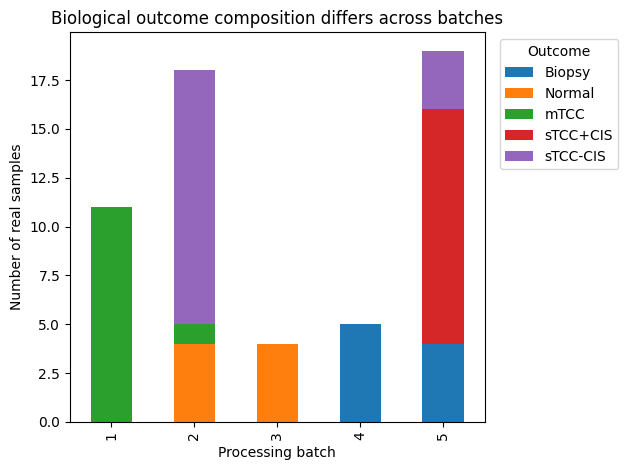

In [38]:
outcome_batch.plot(kind="bar", stacked=True)

plt.xlabel("Processing batch")
plt.ylabel("Number of real samples")
plt.title("Biological outcome composition differs across batches")
plt.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 8. Visualizing batch structure

We will use PCA only as a **diagnostic visualization** here.

The mathematical details of PCA will be covered in a later practical.

## 8.1 Select highly variable features for visualization

Using all 22,283 features is unnecessary for a quick exploratory plot. So we will keep only top 1000 by variation

In [39]:
real_X = real[gene_cols]

feature_variance = real_X.var().sort_values(ascending=False)
top_genes = feature_variance.head(1000).index

X_vis = real_X[top_genes]

## 8.2 Standardize and project to two dimensions

In [40]:
X_scaled = StandardScaler().fit_transform(X_vis)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "batch": real["batch"].astype(str).values,
    "cancer": real["cancer"].astype(str).values,
    "outcome": real["outcome"].astype(str).values
})

print(
    "Explained variance:",
    pca.explained_variance_ratio_.round(3)
)

Explained variance: [0.279 0.166]


## 8.3 Color by batch

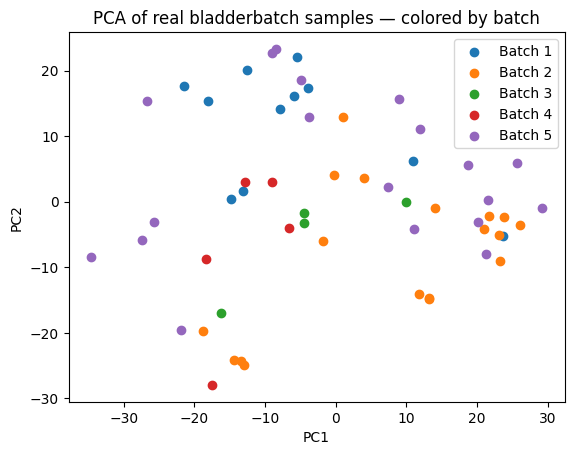

In [41]:
for batch, group in pca_df.groupby("batch"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=f"Batch {batch}"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of real bladderbatch samples — colored by batch")
plt.legend()
plt.show()

## 8.4 Color by cancer class

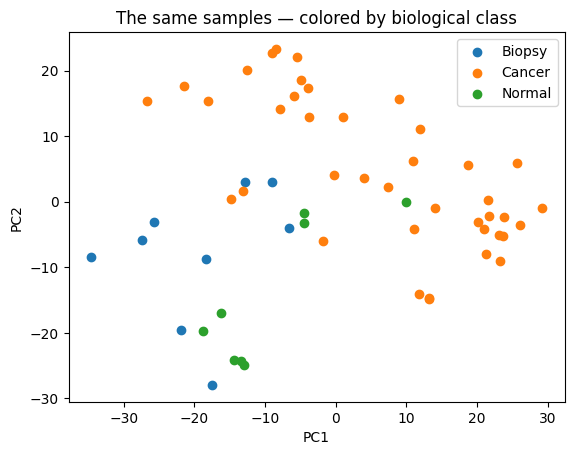

In [42]:
for label, group in pca_df.groupby("cancer"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=label
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("The same samples — colored by biological class")
plt.legend()
plt.show()

### Discussion

Look at the **same geometric arrangement** twice:

1. colored by processing batch;
2. colored by biological target.

If batch and target are associated, how confidently can we interpret a predictive signal as biology?

# 9. Prepare ML-ready train and test sets

Return to the group-aware split.

In [43]:
X_train = train_df[gene_cols].copy()
X_test = test_df[gene_cols].copy()

y_train = train_df["cancer"].copy()
y_test = test_df["cancer"].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (84, 22283)
X_test: (30, 22283)
y_train: (84,)
y_test: (30,)


Check missingness before proceeding.

In [44]:
print("Missing train values:",
      X_train.isna().sum().sum())

print("Missing test values:",
      X_test.isna().sum().sum())

Missing train values: 0
Missing test values: 0



# 11. Independent task - UCI Mice Protein Expression

Now apply the same general workflow to the UCI Mice Protein Expression dataset.

    Data_Cortex_Nuclear.xls

The dataset is available from the UCI Machine Learning Repository at:
https://archive.ics.uci.edu/dataset/342/mice%2Bprotein%2Bexpression

The dataset contains 1,080 rows, expression levels for 77 proteins or protein modifications, measurements from 72 mice, and 15 measurements per mouse. It also includes MouseID, Genotype, Treatment, Behavior, and an eight-level composite class.

### What are the 15 measurements?

For each mouse sample, the original reverse-phase protein array (RPPA) experiment used three technical replicate spots at each point of a five-point dilution series:

    1 mouse × 5 dilution points × 3 technical replicates = 15 rows

The dilution points are different concentrations of the same sample, and the replicate spots are repeated technical measurements. They are not 15 independent mice or 15 biological replicates. The public UCI spreadsheet does not contain separate dilution-level or replicate-number columns, so the exact dilution curve cannot be reconstructed  alone, meaning you need to select one dilution level. In the distributed file, labels such as `309_1` through `309_15` are row-level measurement identifiers: the part before the final underscore identifies the biological mouse, while the suffix identifies the measurement record.

Create a derived grouping variable before splitting:

    mice["mouse_id"] = mice["MouseID"].astype(str).str.rsplit("_", n=1).str[0]

Your goal is to turn the data into a defensible ML-ready dataset while keeping measurement, mouse, experimental-condition, and target roles separate.

## Required tasks

### A. Data presentation

Identify:

- what one row represents and what one biological mouse represents;
- the 77 numerical protein-expression measurements;
- MouseID, derived mouse_id, and the experimental metadata;
- one possible prediction target.

Consider Genotype as a primary target: control versus trisomy. You may choose the eight-level class target instead, but explain why. Remember that class is constructed from genotype, behavior, and treatment.

### B. EDA and tidy-data assessment

- load the Excel file and inspect dimensions, column names, and data types;
- inspect the distributions of Genotype, Treatment, Behavior, and class;
- check how many rows and how many unique mice belong to each group;
- visualize at least three biologically meaningful relationships.

Possible plots include:

- distributions of selected protein measurements by genotype;
- a PCA or two-dimensional projection colored by genotype, treatment, or behavior;
- protein-expression relationships or a correlation heatmap;
- the number of measurements per derived mouse_id.

For every plot, state the biological question it addresses.

### C. Diagnostics

Check:

- missingness in the protein measurements and metadata;
- duplicate rows and duplicate MouseID measurement records;
- whether every mouse has the expected number of repeated measurements;
- unusual categories or inconsistent labels;
- non-finite, negative, or otherwise implausible expression values;
- highly correlated or redundant protein variables;
- whether any candidate predictor is a deterministic part of the target.

### D. Preparation

Choose one supervised-learning problem and create:

    X
    y

Explain every variable that you exclude.

For a genotype-prediction question, start with the 77 protein measurements as candidate features. Exclude:

- MouseID and derived mouse_id, because the raw identifier identifies a measurement record and the derived identifier identifies the biological unit;
- the target column;
- class when Genotype is the target, because it contains genotype information;
- Treatment and Behavior unless you explicitly want a conditional prediction question and can justify their use.

Use the real missing values in the dataset to compare a defensible removal rule with an imputation rule. If you impute, fit the imputer on the training data only and apply it to the test data.

### E. Split

Create an appropriate training/test split.

For generalization to unseen mice:

- derive and group by mouse_id;
- keep all 15 measurements from a mouse in the same partition;
- use a group-aware split such as GroupShuffleSplit or StratifiedGroupKFold when appropriate.

Explain:

- what population you want the model to generalize to;
- why a row-wise random split would give an over-optimistic estimate;
- what the independent biological unit is;
- whether stratification is needed and whether it is compatible with your grouping strategy.

### F. Confounding and distribution structure

Investigate associations between the target and:

- treatment;
- behavior;
- genotype;
- the composite class;
- the number of measurements per mouse.

Use cross-tabulations and plots to ask:

- are treatment and behavior balanced across genotype?
- does the composite class encode the target directly?
- do some mice or experimental groups contribute different numbers of rows?
- could a model exploit experimental design structure instead of protein biology?

Identify at least one plausible source of confounding, target leakage, or distribution shift.

### G. Deliverable

Provide:

- X_train, X_test, y_train, y_test;
- a table documenting the role of each column;
- a missingness report and a justified removal or imputation decision;
- plots if you want;
- a short Markdown interpretation describing:
  - the ML question;
  - the biological unit;
  - the split strategy;
  - one potential source of bias, confounding, or leakage.

## Optional advanced task

Compare two evaluation questions:

1. a random row-wise train/test split;
2. a mouse-grouped train/test split.

Are these evaluating the same kind of generalization?

As a second extension, compare predicting Genotype with predicting the composite class. Which question is biologically clearer, and which variables must be excluded to avoid target leakage?


# 12. Take-home messages

- Biological data should be understood before they are modelled.
- High-dimensional omics commonly have \(p \gg n\).
- Metadata are part of the scientific problem, not administrative decoration.
- Data diagnostics include checking experimental structure, not only detecting `NaN`.
- Similar or repeated observations must remain in the same split.
- Data augmentation and pseudo-replication can produce leakage if derivatives cross the split boundary.
- Batch effects are technical signals that a model can exploit.
- Batch–target confounding makes biological interpretation especially difficult.
- Train/test splitting is part of experimental design.
- A valid ML pipeline begins with a valid scientific question.

In [ ]:
# !pip install xlrd

Defaulting to user installation because normal site-packages is not writeable


### A. Data presentation

In [47]:
from sklearn.model_selection import StratifiedGroupKFold

mice = pd.read_excel(DATA / "Data_Cortex_Nuclear.xls")

print("Shape:", mice.shape)
print(mice.columns.tolist()[:5], "...", mice.columns.tolist()[-5:])
mice.dtypes.value_counts()

Shape: (1080, 82)
['MouseID', 'DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N'] ... ['CaNA_N', 'Genotype', 'Treatment', 'Behavior', 'class']


float64    77
object      5
Name: count, dtype: int64

In [ ]:
meta_cols = ["MouseID", "Genotype", "Treatment", "Behavior", "class"]
protein_cols = [c for c in mice.columns if c not in meta_cols]
print("Number of protein columns:", len(protein_cols))

mice["mouse_id"] = mice["MouseID"].astype(str).str.rsplit("_", n=1).str[0]

print("Rows:", len(mice))
print("Unique mice:", mice["mouse_id"].nunique())
mice[["MouseID", "mouse_id", "Genotype", "Treatment", "Behavior", "class"]].head()

Number of protein columns: 77
Rows: 1080
Unique mice: 72


,MouseID,mouse_id,Genotype,Treatment,Behavior,class
0,309_1,309,Control,Memantine,C/S,c-CS-m
1,309_2,309,Control,Memantine,C/S,c-CS-m
2,309_3,309,Control,Memantine,C/S,c-CS-m
3,309_4,309,Control,Memantine,C/S,c-CS-m
4,309_5,309,Control,Memantine,C/S,c-CS-m


One row is a single technical measurement, not an animal. The independent biological unit is the mouse (`mouse_id`): 72 mice × 15 rows = 1,080 rows. The public file has no dilution or replicate column, so one dilution level cannot be selected; all 15 rows of a mouse are therefore kept and handled through grouping.

Column roles:

- Features: 77 numerical protein/modification levels (`*_N` columns).
- Identifiers: `MouseID` (identifies a *measurement record*) and the derived `mouse_id` (identifies the *mouse*; grouping variable).
- Experimental metadata: `Genotype`, `Treatment`, `Behavior` and the composite `class` (genotype × behavior × treatment).
- Target: `Genotype` (Control vs Ts65Dn/trisomy). It is binary and isolates one biological factor. `class` was not chosen as the primary target because it mixes three factors, and it must be excluded from the features whenever `Genotype` is the target because it contains genotype information.

### B. EDA and tidy-data assessment

In [51]:
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(f"\nEDA for col: {col}")
    summary = pd.DataFrame({
        "rows": mice[col].value_counts(),
        "unique_mice": mice.groupby(col)["mouse_id"].nunique(),
    })
    print(summary)


EDA for col: Genotype
          rows  unique_mice
Genotype                   
Control    570           38
Ts65Dn     510           34

EDA for col: Treatment
           rows  unique_mice
Treatment                   
Memantine   570           38
Saline      510           34

EDA for col: Behavior
          rows  unique_mice
Behavior                   
C/S        525           35
S/C        555           37

EDA for col: class
        rows  unique_mice
class                    
c-CS-m   150           10
c-CS-s   135            9
c-SC-m   150           10
c-SC-s   135            9
t-CS-m   135            9
t-CS-s   105            7
t-SC-m   135            9
t-SC-s   135            9


Rows and unique mice are not proportional only by construction: every mouse contributes exactly 15 rows, so rows = 15 × mice in every group. At the mouse level the design is slightly unbalanced (Control 38 vs Ts65Dn 34; the smallest composite class, `t-CS-s`, has only 7 mice).

/var/folders/fk/vvlpwk9n4v9cm1236srvm4n40000gn/T/ipykernel_29282/3358085859.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data, labels=genotypes)


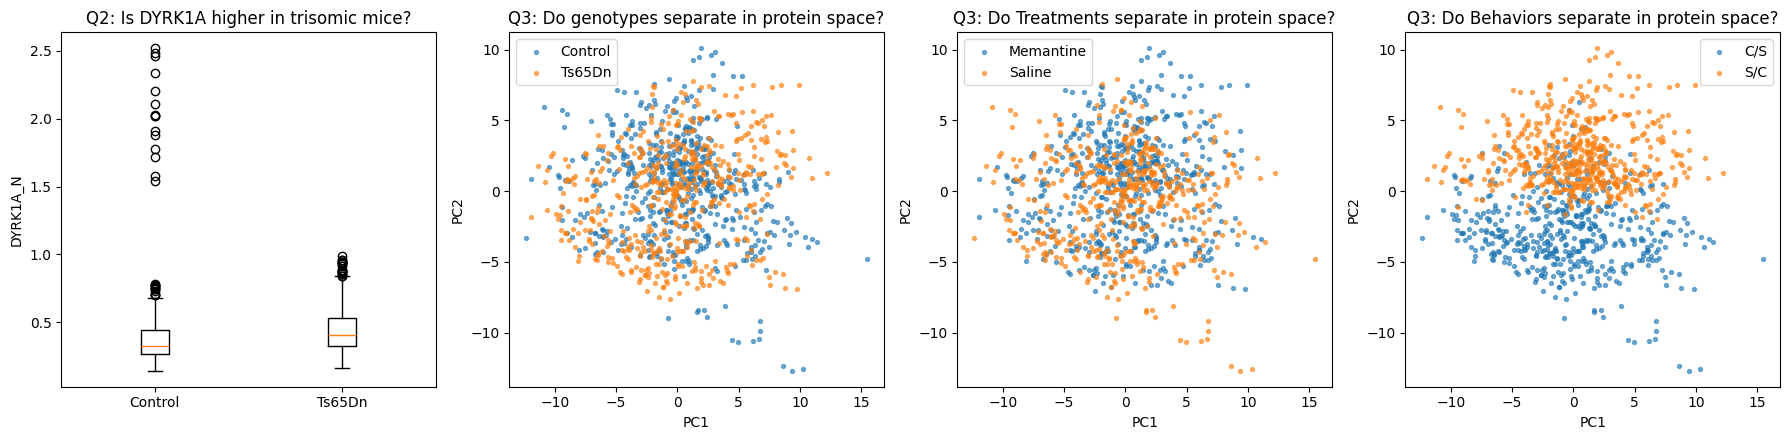

In [60]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))


genotypes = mice["Genotype"].dropna().unique()
treatments = mice["Treatment"].dropna().unique()
behaviors = mice["Behavior"].dropna().unique()

data = [mice.loc[mice["Genotype"] == g, "DYRK1A_N"].dropna() for g in genotypes]
axes[0].boxplot(data, labels=genotypes)
axes[0].set_ylabel("DYRK1A_N")
axes[0].set_title("Q2: Is DYRK1A higher in trisomic mice?")

X_vis = SimpleImputer(strategy="median").fit_transform(mice[protein_cols])
pcs = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X_vis))
for g in genotypes:
    m = (mice["Genotype"] == g).to_numpy()
    axes[1].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.6, label=g)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Q3: Do genotypes separate in protein space?")
axes[1].legend()

X_vis = SimpleImputer(strategy="median").fit_transform(mice[protein_cols])
pcs = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X_vis))
for g in treatments:
    m = (mice["Treatment"] == g).to_numpy()
    axes[2].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.6, label=g)
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
axes[2].set_title("Q3: Do Treatments separate in protein space?")
axes[2].legend()

X_vis = SimpleImputer(strategy="median").fit_transform(mice[protein_cols])
pcs = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X_vis))
for g in behaviors:
    m = (mice["Behavior"] == g).to_numpy()
    axes[3].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=0.6, label=g)
axes[3].set_xlabel("PC1"); axes[3].set_ylabel("PC2")
axes[3].set_title("Q3: Do Behaviors separate in protein space?")
axes[3].legend()

plt.tight_layout()
plt.show()

only behaviors have +- separate logics, yet still those are not clear clusters

1. DYRK1A_N by genotype — is DYRK1A higher in trisomic mice?** The gene lies in the triplicated region, so a dosage effect is expected. The median is slightly higher in Ts65Dn, but the distributions overlap heavily, and the Control group contains a set of high outliers (≈1.5–2.5); it is worth checking whether they come from a few mice. DYRK1A alone is not a clean separator.
2. PCA coloured by genotype -- no clear separation.
3. PCA coloured by treatment -- no visible separation.
4. PCA coloured by behavior -- C/S and S/C separate fairly clearly along PC2. The largest source of variation in protein space is the behavioral context, not genotype. This is a signal for genotype prediction.

genotype classification is expected to be difficult, and design variables must be examined for confounding

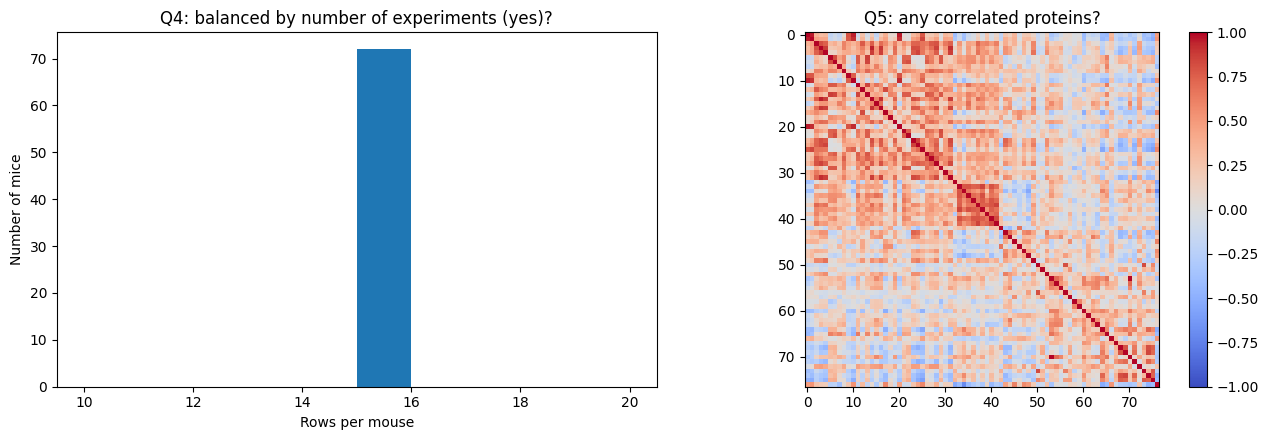

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cnt = mice.groupby("mouse_id").size()
axes[0].hist(cnt, bins=range(10, 21))
axes[0].set_xlabel("Rows per mouse"); axes[0].set_ylabel("Number of mice")
axes[0].set_title("Q4: balanced by number of experiments (yes)?")

corr = mice[protein_cols].corr()
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("Q5: any correlated proteins?")
plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

5. every of the 72 mice has 15 rows.
6. mostly moderate positive correlations, with a visible block of strongly correlated proteins (around 33–41)

In [75]:
na_prot = mice[protein_cols].isna().sum().sort_values(ascending=False)
print("Proteins with any NA:", (na_prot > 0).sum(), "of", len(protein_cols))
print("Total missing protein cells:", int(na_prot.sum()),
      f"({na_prot.sum() / mice[protein_cols].size:.2%})")
display(na_prot.head(10))
print("Missing in metadata:\n", mice[meta_cols + ["mouse_id"]].isna().sum())

print("\nDuplicate rows:", mice.duplicated().sum())
print("Duplicate MouseID:", mice["MouseID"].duplicated().sum())

cnt = mice.groupby("mouse_id").size()
print("Mice with != 15 rows:\n", cnt[cnt != 15])

for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(col, "->", sorted(mice[col].dropna().unique()))

vals = mice[protein_cols]
print("\nInf values:", np.isinf(vals.to_numpy(dtype=float)).sum())
print("Negative values:", (vals < 0).sum().sum())
print("Min / max:", vals.min().min(), vals.max().max())

corr = vals.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack()
high_pairs = high_pairs[high_pairs > 0.95].sort_values(ascending=False)
print("\nProtein pairs with |r| > 0.95:", len(high_pairs))
display(high_pairs.head(10))

print("\nGenotype vs class crosstab:")
print(pd.crosstab(mice["class"], mice["Genotype"]))

print("\nARC_N vs pS6_N max abs diff:", (mice["ARC_N"] - mice["pS6_N"]).abs().max())
print("ARC_N and pS6_N identical incl. NaN pattern:", mice["ARC_N"].equals(mice["pS6_N"]))

Proteins with any NA: 49 of 77
Total missing protein cells: 1396 (1.68%)


BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
ELK_N          18
Bcatenin_N     18
MEK_N           7
P38_N           3
dtype: int64

Missing in metadata:
 MouseID      0
Genotype     0
Treatment    0
Behavior     0
class        0
mouse_id     0
dtype: int64

Duplicate rows: 0
Duplicate MouseID: 0
Mice with != 15 rows:
 Series([], dtype: int64)
Genotype -> ['Control', 'Ts65Dn']
Treatment -> ['Memantine', 'Saline']
Behavior -> ['C/S', 'S/C']
class -> ['c-CS-m', 'c-CS-s', 'c-SC-m', 'c-SC-s', 't-CS-m', 't-CS-s', 't-SC-m', 't-SC-s']

Inf values: 0
Negative values: 1
Min / max: -0.062007874 8.482553422

Protein pairs with |r| > 0.95: 3


ARC_N     pS6_N      1.000000
DYRK1A_N  BRAF_N     0.959578
          ITSN1_N    0.959512
dtype: float64


Genotype vs class crosstab:
Genotype  Control  Ts65Dn
class                    
c-CS-m        150       0
c-CS-s        135       0
c-SC-m        150       0
c-SC-s        135       0
t-CS-m          0     135
t-CS-s          0     105
t-SC-m          0     135
t-SC-s          0     135

ARC_N vs pS6_N max abs diff: 0.0
ARC_N and pS6_N identical incl. NaN pattern: True


In [76]:
neg = mice[protein_cols].lt(0).stack()
for row, protein in neg[neg].index:
    print(protein, "=", mice.loc[row, protein],
          "|", mice.loc[row, ["MouseID", "Genotype", "Treatment", "Behavior"]].to_dict())

RRP1_N = -0.062007874 | {'MouseID': '365_14', 'Genotype': 'Control', 'Treatment': 'Memantine', 'Behavior': 'S/C'}


- Missing values occur only in protein columns (1,396 cells = 1.68%; 49 of 77 proteins affected; highest: `BCL2_N`, `H3MeK4_N`, `BAD_N`, `EGR1_N`, `H3AcK18_N`, `pCFOS_N`). The metadata have no missing values. The missingness structure is analysed in section D.
- no duplicate rows, no duplicate `MouseID`; every mouse has exactly 15 rows.
- all category labels are consistent (2 genotypes, 2 treatments, 2 behaviors, 8 classes); no unexpected categories.
- no infinite values; one slightly negative value (−0.062), a single cell very close to zero, most likely a normalization/background artifact. Decision: keep it, since it is immaterial.
- `ARC_N` and `pS6_N` are exactly identical, so `pS6_N` is removed in section D. `DYRK1A_N` correlates with `BRAF_N` and `ITSN1_N` at |r| ≈ 0.96; this is biologically plausible co-variation, so these features are kept (a model with regularization or PCA can handle it).
- `class` fully determines `Genotype` (the `c-`/`t-` prefix maps one-to-one to Control/Ts65Dn; see crosstab), so it is a direct leak and must not be a feature.

### D. Preparation

First define `X`, `y` and the grouping variable. Detection of missing values uses the full table because it is a diagnostic, not a fitted transformation.

In [62]:
target_col = "Genotype"

mice_model = mice.dropna(subset=[target_col]).reset_index(drop=True)

X = mice_model[protein_cols].copy()
y = mice_model[target_col].copy()
groups = mice_model["mouse_id"].copy()

print("X:", X.shape, "| y:", y.shape, "| groups:", groups.nunique())

X: (1080, 77) | y: (1080,) | groups: 72


In [77]:
miss_report = (mice[protein_cols].isna().sum().rename("n_missing").to_frame()
               .assign(pct=lambda d: (d.n_missing / len(mice) * 100).round(2)))
miss_report = miss_report[miss_report.n_missing > 0].sort_values("n_missing", ascending=False)
print(miss_report.head(10))

top = miss_report.index[:6]
struct = {p: int(mice.groupby("mouse_id")[p].apply(lambda s: s.isna().all()).sum()) for p in top}
print("\nMice in which the protein is missing in all 15 rows (structural missingness):", struct)

print("\nFraction of missing values by genotype:")
print(mice.groupby("Genotype")[list(top)].apply(lambda d: d.isna().mean()).round(3))

full_na = mice.groupby("mouse_id")[list(top)].agg(lambda s: s.isna().all())
geno_by_mouse = mice.groupby("mouse_id")["Genotype"].first()
print("\nMice with the protein missing in all rows, by genotype:")
print(full_na.groupby(geno_by_mouse).sum())

            n_missing    pct
BCL2_N            285  26.39
H3MeK4_N          270  25.00
BAD_N             213  19.72
EGR1_N            210  19.44
H3AcK18_N         180  16.67
pCFOS_N            75   6.94
ELK_N              18   1.67
Bcatenin_N         18   1.67
MEK_N               7   0.65
P38_N               3   0.28

Mice in which the protein is missing in all 15 rows (structural missingness): {'BCL2_N': 19, 'H3MeK4_N': 18, 'BAD_N': 14, 'EGR1_N': 14, 'H3AcK18_N': 12, 'pCFOS_N': 5}

Fraction of missing values by genotype:
          BCL2_N  H3MeK4_N  BAD_N  EGR1_N  H3AcK18_N  pCFOS_N
Genotype                                                     
Control    0.289     0.342  0.242   0.211      0.184    0.053
Ts65Dn     0.235     0.147  0.147   0.176      0.147    0.088

Mice with the protein missing in all rows, by genotype:
          BCL2_N  H3MeK4_N  BAD_N  EGR1_N  H3AcK18_N  pCFOS_N
Genotype                                                     
Control       11        13      9       8  

- The five worst proteins have 16–26% missing values, and `pCFOS_N` has 7%; all other proteins are below 2%.
- The missingness is structural at mouse level, not random at spot level: the counts are (almost exactly) multiples of 15 (e.g. `BCL2_N` 285 = 19 mice × 15 rows), i.e. a protein was simply not measured/reported for whole mice.
- It is not independent of the target: Control mice have noticeably more missing values than Ts65Dn for `H3MeK4_N` (34% vs 15%) and `BAD_N` (24% vs 15%).
- dropping incomplete rows is very costly; imputing a protein that is missing for a quarter of the mice with a single median invents data for whole animals, and the missingness pattern itself could carry design/genotype information. Features with high missingness are therefore removed, and the few remaining sporadic gaps are imputed.

### E. Split

In [63]:
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))

X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print("Mouse overlap:", set(groups_train) & set(groups_test))
print("Train mice:", groups_train.nunique(), "| Test mice:", groups_test.nunique())
print("\nTrain genotype share:\n", y_train.value_counts(normalize=True).round(2))
print("Test genotype share:\n", y_test.value_counts(normalize=True).round(2))
print("\nRows per mouse in test:", groups_test.value_counts().unique())

Mouse overlap: set()
Train mice: 54 | Test mice: 18

Train genotype share:
 Genotype
Control    0.54
Ts65Dn     0.46
Name: proportion, dtype: float64
Test genotype share:
 Genotype
Control    0.5
Ts65Dn     0.5
Name: proportion, dtype: float64

Rows per mouse in test: [15]


Generalization population: new, unseen mice.

Independent biological unit: the mouse, not the row. All 15 measurements of a single mouse are replicates of the same sample.

a row-wise split overestimates performance: measurements from the same mouse are nearly identical, so a test row has "twins" in the training set. The model memorizes the mouse rather than learning the underlying biology.

Stratification: useful because there are only 72 mice and a random group split could easily give an unbalanced genotype ratio. It is compatible with grouping when `StratifiedGroupKFold` is used: it stratifies the groups (mice), not the rows, so the genotype proportions are preserved approximately rather than exactly. This is a standard and expected trade-off.

In [78]:
complete = X_train_raw.dropna()
print(f"Complete-row removal keeps {len(complete)} / {len(X_train_raw)} training rows "
      f"({groups_train.loc[complete.index].nunique()} / {groups_train.nunique()} mice)")

na_frac_train = X_train_raw.isna().mean()
print(f"Removing every feature with any NA would keep {int((na_frac_train == 0).sum())} / {len(protein_cols)} features")

dropped_na = na_frac_train[na_frac_train > 0.05].index.tolist()
redundant = ["pS6_N"]
keep_cols = [c for c in protein_cols if c not in dropped_na and c not in redundant]
print(f"Chosen rule: drop {len(dropped_na)} features with >5% NA {dropped_na} and redundant {redundant}; "
      f"keep {len(keep_cols)} features")

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw[keep_cols]),
                       columns=keep_cols, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw[keep_cols]),
                      columns=keep_cols, index=X_test_raw.index)
print("NA train/test:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| y_train:", y_train.shape, "| y_test:", y_test.shape)

Complete-row removal keeps 447 / 810 training rows (30 / 54 mice)
Removing every feature with any NA would keep 28 / 77 features
Chosen rule: drop 6 features with >5% NA ['BAD_N', 'BCL2_N', 'pCFOS_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N'] and redundant ['pS6_N']; keep 70 features
NA train/test: 0 0
X_train: (810, 70) | X_test: (270, 70) | y_train: (810,) | y_test: (270,)


In [79]:
roles = pd.DataFrame([
    ("77 proteins (protein_cols)", "feature", "used (except those dropped due to missing values)"),
    ("MouseID", "measurement identifier", "excluded: unique record ID"),
    ("mouse_id", "group / biological unit", "excluded from X; used for GroupSplit"),
    ("Genotype", "target", "y"),
    ("class", "composite label", "excluded: contains genotype (leakage)"),
    ("Treatment", "experimental condition", "excluded: changes the research question, confounder"),
    ("Behavior", "experimental condition", "excluded: changes the research question, confounder"),
], columns=["column", "role", "decision"])
roles

,column,role,decision
0,77 proteins (protein_cols),feature,used (except those dropped due to missing values)
1,MouseID,measurement identifier,excluded: unique record ID
2,mouse_id,group / biological unit,excluded from X; used for GroupSplit
3,Genotype,target,y
4,class,composite label,excluded: contains genotype (leakage)
5,Treatment,experimental condition,"excluded: changes the research question, confo..."
6,Behavior,experimental condition,"excluded: changes the research question, confo..."


### F. Confounding and distribution structure

Genotype x Treatment (mice):
Treatment  Memantine  Saline  All
Genotype                         
Control           20      18   38
Ts65Dn            18      16   34
All               38      34   72

Genotype x Behavior (mice):
Behavior  C/S  S/C  All
Genotype               
Control    19   19   38
Ts65Dn     16   18   34
All        35   37   72

Composite class x Genotype:
Genotype  Control  Ts65Dn
cls                      
c-CS-m         10       0
c-CS-s          9       0
c-SC-m         10       0
c-SC-s          9       0
t-CS-m          0       9
t-CS-s          0       7
t-SC-m          0       9
t-SC-s          0       9

Rows per mouse by genotype:
          count  mean  std   min   25%   50%   75%   max
Genotype                                                
Control    38.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0
Ts65Dn     34.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0


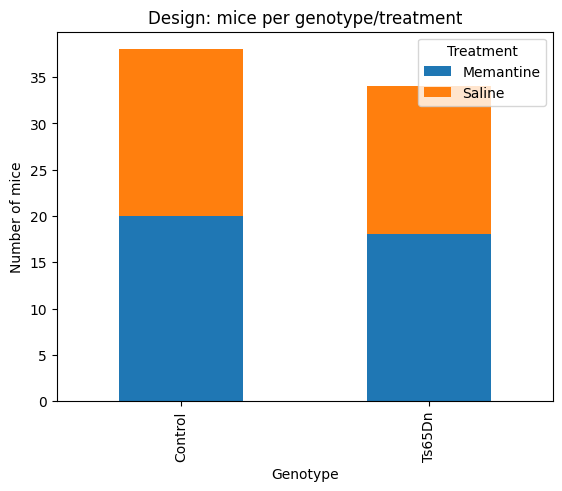

In [80]:
mouse_level = (mice_model.groupby("mouse_id")
               .agg(Genotype=("Genotype", "first"),
                    Treatment=("Treatment", "first"),
                    Behavior=("Behavior", "first"),
                    cls=("class", "first"),
                    n_rows=("MouseID", "size"))
               .reset_index())

print("Genotype x Treatment (mice):")
print(pd.crosstab(mouse_level["Genotype"], mouse_level["Treatment"], margins=True))
print("\nGenotype x Behavior (mice):")
print(pd.crosstab(mouse_level["Genotype"], mouse_level["Behavior"], margins=True))
print("\nComposite class x Genotype:")
print(pd.crosstab(mouse_level["cls"], mouse_level["Genotype"]))
print("\nRows per mouse by genotype:")
print(mouse_level.groupby("Genotype")["n_rows"].describe())

mouse_level.groupby(["Genotype", "Treatment"]).size().unstack().plot(
    kind="bar", stacked=True)
plt.ylabel("Number of mice"); plt.title("Design: mice per genotype/treatment")
plt.show()

In [81]:
from scipy.stats import fisher_exact

for col in ["Treatment", "Behavior"]:
    ct = pd.crosstab(mouse_level["Genotype"], mouse_level[col])
    odds, p = fisher_exact(ct)
    print(f"Genotype x {col}: p = {p:.3f}")

Genotype x Treatment: p = 1.000
Genotype x Behavior: p = 0.818


- Treatment and Behavior are approximately balanced across genotype at the mouse level (Fisher exact test: Genotype × Treatment p = 1.000, Genotype × Behavior p = 0.818). Neither can serve as a proxy for genotype, so there is no strong design confounding. With only 72 mice the tests have limited power, so this means "no evidence of imbalance", not proof of balance.
- Composite class: direct target leakage; the c-/t- prefix determines genotype exactly.
- Rows per mouse: exactly 15 for every mouse and genotype, so there is no recording-frequency bias.
- Behavior as a nuisance factor: it is the dominant axis of variation in the PCA (section B) although it is unrelated to genotype. A model must find the genotype signal underneath a larger design-related signal.
- Treatment × genotype interaction (distribution shift): memantine was used in the original study to rescue the trisomic phenotype, so protein profiles of treated Ts65Dn mice may move toward controls. Genotype is then not a homogeneous class, and results can depend on how treated and untreated mice fall into the folds.
- Missingness pattern: it is mouse-level and differs by genotype (section D), so any rule that keeps those proteins can exploit the missingness pattern instead of protein biology.
- Small number of mice: with 72 mice, performance is very sensitive to fold composition. The single split above gives a 50/50 genotype ratio in test and 54/46 in train; cross-validation (see the optional task) is needed for a stable estimate.
- Unobserved batch effects: processing days or batches are not recorded, so hidden batch effects cannot be excluded.

### G.

ML question. Predict the genotype (Control / Ts65Dn) of new, unseen mice from the expression profile of 70 proteins.

Biological unit. The mouse (72 mice, 15 technical measurements each).

Split strategy. `StratifiedGroupKFold` grouped by `mouse_id` (4 folds, first fold used; train = 54 mice, test = 18 mice). All 15 rows of a mouse stay in the same partition; genotype proportions are approximately preserved.

Why not a row-wise split. Rows of the same mouse are nearly identical, so a test row has "twins" in the training set and the model can memorize individual mice. In the optional experiment below, accuracy is 0.978 with a row-wise split versus 0.774 with the mouse-grouped split.

Main sources of bias, confounding or leakage.
1. `class` encodes genotype (direct leakage; excluded).
2. Behavior dominates the protein-space variation and treatment may interact with genotype; both are balanced across genotype but remain nuisance variation.
3. Missingness is mouse-level and differs by genotype.
4. Only 72 mice, so any single split gives a noisy estimate.

In [82]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def eval_split(tr, te, label):
    clf = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        LogisticRegression(max_iter=2000))
    clf.fit(X.iloc[tr], y.iloc[tr])
    print(f"{label}: accuracy = {clf.score(X.iloc[te], y.iloc[te]):.3f}")

tr_r, te_r = train_test_split(np.arange(len(X)), test_size=0.25,
                              stratify=y, random_state=RANDOM_STATE)
eval_split(tr_r, te_r, "Row-wise split  ")
eval_split(train_idx, test_idx, "Mouse-grouped    ")

Row-wise split  : accuracy = 0.978
Mouse-grouped    : accuracy = 0.774


A row-wise split evaluates whether the model can recognize new measurements from a mouse it has already seen, whereas a grouped split evaluates whether it generalizes to entirely new mice. Only the latter answers the actual biological question.

Predicting Genotype is biologically cleaner because it isolates a single biological factor. class conflates genotype, behavior, and treatment; moreover, it must be excluded when predicting Genotype to avoid target leakage.

# 13. Data-preparation readiness checklist

Use this checklist before starting any biological machine-learning analysis. Tick an item only after inspecting the data or documenting a justified decision. It is dataset-independent and can be reused in later practicals.

## Scientific purpose and provenance

- [ ] Is the biological question and prediction task stated clearly?
- [ ] Is the unit of observation clear (for example, patient, tissue, cell, mouse, or technical measurement)?
- [ ] Do I know where the data came from, how they were generated, and under which license or access conditions they may be used?
- [ ] Have I recorded the data version, processing history, and transformations already applied?

## Table shape and identifiers

- [ ] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [ ] If the original assay has features in rows and samples in columns, have I transposed it into the format expected by the analysis tool?
- [ ] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?
- [ ] Can every feature and observation be traced back to its source?
- [ ] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?

## Types, values, and measurement meaning

- [ ] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [ ] Are units, scales, encodings, reference categories, and detection limits understood?
- [ ] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?
- [ ] Are normalization, scaling, log transformation, and batch-correction steps documented?

## Missing values

- [ ] Have I detected missing values using the dataset's actual missing-value representations, not only `NaN`?
- [ ] Have I measured missingness by row, column, group, and relevant batch or time variable?
- [ ] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?
- [ ] Have I justified whether to retain, remove, or impute missing values?
- [ ] If imputing, will the imputer be fitted on training data only and then applied to validation/test data?

## Replicates, dependence, and grouping

- [ ] Have I checked for exact duplicates and near-duplicate observations?
- [ ] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [ ] Is the independent biological unit identified by a grouping variable?
- [ ] Will all related observations and their derivatives remain in the same train/validation/test split?
- [ ] If I created augmented or synthetic observations, is their provenance recorded and reproducible?

## Target, leakage, and study design

- [ ] Is the target defined before modelling, with its classes or values checked for balance and validity?
- [ ] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?
- [ ] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?
- [ ] Have I checked whether the target is associated with a technical or grouping variable?
- [ ] Does the planned split represent the biological generalization question?

## Reproducibility and decision record

- [ ] Are random seeds, software versions, file names, and input/output shapes recorded?
- [ ] Are all preprocessing steps placed in a reproducible pipeline?
- [ ] Have I recorded unresolved data-quality concerns and the decisions made about them?
- [ ] Can another person explain what each row, column, feature, target, and grouping variable means?

## Short preparation summary

Before modelling, write down:

- biological unit: mouse_id (mouse)
- number of observations and features: 1,080 rows, 72 mice, 77 proteins (71 after filtering)
- target and feature definition: Genotype; protein expression levels
- missing-value decision: Drop 6 features with >5% missing values, impute the rest with the median (fitted on the training set)
- replicate/grouping decision: Group by mouse_id
- main confounder or possible leakage source: class (encodes genotype); Treatment/Behavior
- train/test split and why it is appropriate: StratifiedGroupKFold by mouse_id; ensures proper generalization to new, unseen mice
- remaining concerns: Small sample size (few mice), unknown batch effects, a single negative value, and duplicated features (ARC_N / pS6_N)

ai usage report: i asked copilot to polish texts from grammatical side and it is also enabled for code suggestions in my vs code